# Laboratorium 2 — wprowadzenie do Keras

W tym ćwiczeniu zbudujesz i wytrenujesz małą sieć neuronową do klasyfikacji binarnej. Skupimy się na przepływie pracy w Keras, a nie na implementowaniu algorytmu uczenia od podstaw. Zakładamy znajomość Pythona i podstaw pracy w Colabie.

**Cele:** przygotować dane i sprawdzić ich kształty, zdefiniować model `Sequential`, skonfigurować go przez `compile()`, trenować przez `fit()`, obserwować przebieg uczenia, ocenić model na odłożonym zbiorze testowym i wykonać predykcje.

## 1. Przygotowanie środowiska

Otwórz kopię notebooka w Google Colab i połącz się ze środowiskiem wykonawczym. Do tego przykładu wystarczy domyślne CPU — GPU nie jest wymagane. Komórki uruchamiaj po kolei od góry. W Colabie TensorFlow jest zwykle dostępny w środowisku; nie instalujemy pakietów bez potrzeby.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


Jeśli import TensorFlow się nie powiedzie, najpierw sprawdź, czy środowisko Colaba jest połączone i uruchomione. Nie instaluj losowych wersji pakietu — wersje TensorFlow/Keras powinny być zgodne ze środowiskiem kursu.

## 2. Dane do przykładu

Żeby ćwiczenie nie zależało od pobierania danych ani prywatnych plików, wygenerujemy niewielki, sztuczny zbiór. Każda próbka ma dwie cechy liczbowe. Etykieta wynosi 1, gdy suma cech jest dodatnia, i 0 w przeciwnym przypadku. Model będzie uczył się przybliżać tę regułę.

Macierz cech `X` ma kształt `(liczba_próbek, liczba_cech)`, a `y` zawiera etykiety. Losowanie z ustalonym ziarnem ułatwia odtworzenie tego samego przykładu.

In [ ]:
rng = np.random.default_rng(42)
X = rng.normal(size=(600, 2)).astype("float32")
y = (X[:, 0] + X[:, 1] > 0).astype("float32").reshape(-1, 1)

print("X — kształt:", X.shape)
print("y — kształt:", y.shape)
print("Pierwsze trzy próbki:\n", X[:3])
print("Ich etykiety:\n", y[:3].ravel())

X — kształt: (600, 2)
y — kształt: (600, 1)
Pierwsze trzy próbki:
 [[ 0.3047171 -1.0399841]
 [ 0.7504512  0.9405647]
 [-1.9510351 -1.3021795]]
Ich etykiety:
 [0. 1. 0.]


### Podział na zbiory

Zbiór treningowy służy do dopasowania wag modelu, walidacyjny do obserwowania wyników podczas eksperymentów, a testowy do końcowej oceny wybranego modelu. Zbioru testowego nie używamy do podejmowania decyzji o architekturze ani parametrach.

In [ ]:
indeksy = rng.permutation(len(X))
indeks_trening = indeksy[:420]
indeks_walidacja = indeksy[420:510]
indeks_test = indeksy[510:]

X_train, y_train = X[indeks_trening], y[indeks_trening]
X_val, y_val = X[indeks_walidacja], y[indeks_walidacja]
X_test, y_test = X[indeks_test], y[indeks_test]

print("train:", X_train.shape, y_train.shape)
print("validation:", X_val.shape, y_val.shape)
print("test:", X_test.shape, y_test.shape)

train: (420, 2) (420, 1)
validation: (90, 2) (90, 1)
test: (90, 2) (90, 1)


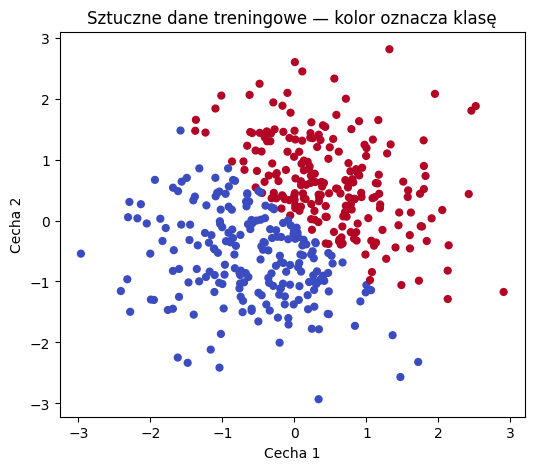

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.ravel(), cmap="coolwarm", s=24)
plt.xlabel("Cecha 1")
plt.ylabel("Cecha 2")
plt.title("Sztuczne dane treningowe — kolor oznacza klasę")
plt.show()

## 3. Model `Sequential`

W Keras model składa się z warstw. W tym przykładzie użyjemy kolejno: warstwy wejściowej dla dwóch cech, małej warstwy ukrytej z aktywacją ReLU i jednego neuronu wyjściowego z sigmoidem. Sigmoid zwraca wartość z przedziału 0–1, którą w tym zadaniu interpretujemy jako wynik dla klasy 1.

`Sequential` jest wygodny, gdy warstwy tworzą jeden prosty ciąg. Kształt wejścia opisuje liczbę cech jednej próbki; liczba próbek (batch) jest dobierana osobno.

In [ ]:
model = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33 (132.00 B)

 Trainable params: 33 (132.00 B)

 Non-trainable params: 0 (0.00 B)

W podsumowaniu sprawdź, czy kształt wejścia odpowiada dwóm cechom, a ostatnia warstwa zwraca jedną wartość na próbkę. Liczba parametrów to wagi i biasy, które model będzie dopasowywał.

## 4. Konfiguracja modelu: `compile()`

Przed treningiem określamy trzy rzeczy:

- **optymalizator** — sposób aktualizowania wag; użyjemy Adam;
- **funkcję straty** — miarę błędu, którą model minimalizuje; dla etykiet 0/1 i wyjścia sigmoid wybieramy `binary_crossentropy`;
- **metrykę** — wynik pomocny do monitorowania; `accuracy` to udział poprawnie sklasyfikowanych przykładów.

Strata i metryka pełnią różne role: model uczy się na podstawie funkcji straty, a metryka ułatwia interpretację postępu.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

## 5. Trenowanie: `fit()`

Epoka to jedno przejście modelu przez cały zbiór treningowy. `batch_size` określa liczbę próbek przetwarzanych naraz. `validation_data` przekazuje dane, na których po każdej epoce mierzymy wyniki, ale nie aktualizujemy na nich wag.

Uruchom trening i zwróć uwagę na czas wykonania oraz to, jakie wartości zapisuje historia.

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0,
)
print("Dostępne wpisy historii:", history.history.keys())
print("Ostatnia strata treningowa:", history.history["loss"][-1])
print("Ostatnia strata walidacyjna:", history.history["val_loss"][-1])

Dostępne wpisy historii: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])
Ostatnia strata treningowa: 0.021212734282016754
Ostatnia strata walidacyjna: 0.030015435069799423


Obiekt zwrócony przez `fit()` zawiera historię metryk z kolejnych epok. Zestawienie treningu i walidacji pomaga zauważyć, czy poprawa na danych treningowych idzie w parze z poprawą na nowych danych.

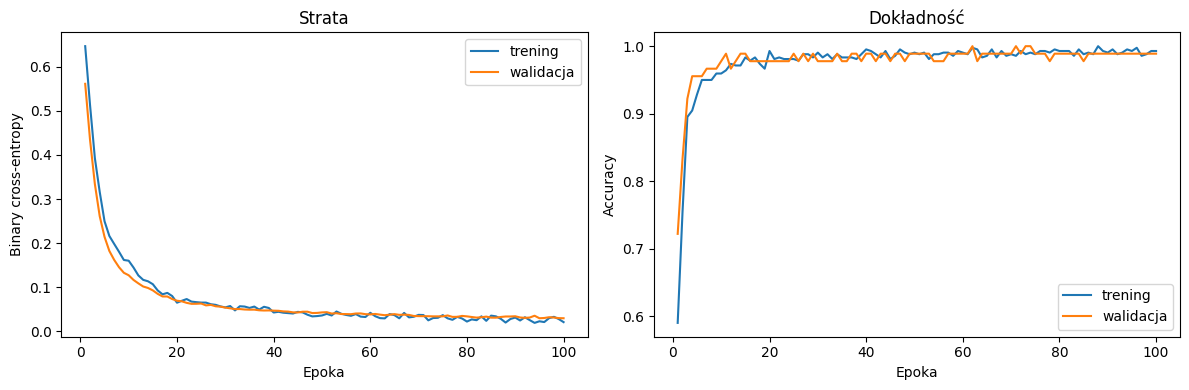

In [ ]:
epoki = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epoki, history.history["loss"], label="trening")
plt.plot(epoki, history.history["val_loss"], label="walidacja")
plt.xlabel("Epoka")
plt.ylabel("Binary cross-entropy")
plt.title("Strata")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoki, history.history["accuracy"], label="trening")
plt.plot(epoki, history.history["val_accuracy"], label="walidacja")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.title("Dokładność")
plt.legend()
plt.tight_layout()
plt.show()

### Zinterpretuj wykresy

1. Czy strata treningowa maleje?
2. Jak zachowuje się strata walidacyjna?
3. Czy wyniki na treningu i walidacji są podobne? Co mogłoby oznaczać, gdyby trening poprawiał się dalej, a walidacja zaczęła się pogarszać?

Nie zakładaj z góry idealnego przebiegu: wyniki mogą nieco różnić się między środowiskami i wersjami bibliotek.

## 6. Ocena i predykcja

Po zakończeniu eksperymentów oceniamy wybrany model na zbiorze testowym. To końcowy pomiar na danych, których nie używaliśmy do uczenia ani wyboru wariantu. `evaluate()` zwraca stratę i skonfigurowane metryki.

In [ ]:
wynik_testowy = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
print(wynik_testowy)

{'accuracy': 1.0, 'loss': 0.04200144484639168}


`predict()` zwraca wartości modelu, tutaj prawdopodobieństwa dla klasy 1. Aby zamienić je na etykiety 0/1, w tym demonstracyjnym przykładzie zastosujemy próg 0.5. W praktycznych zadaniach próg powinien wynikać z celu i kosztu pomyłek.

In [ ]:
prawdopodobienstwa = model.predict(X_test[:5], verbose=0).ravel()
przewidziane_etykiety = (prawdopodobienstwa >= 0.5).astype(int)
print("Prawdziwe etykiety:   ", y_test[:5].ravel().astype(int))
print("Prawdopodobieństwa:   ", np.round(prawdopodobienstwa, 3))
print("Przewidziane etykiety:", przewidziane_etykiety)

Prawdziwe etykiety:    [1 1 0 1 0]
Prawdopodobieństwa:    [1.    0.795 0.012 1.    0.012]
Przewidziane etykiety: [1 1 0 1 0]


## 7. Zadania do samodzielnego wykonania

1. Zmień liczbę neuronów w warstwie ukrytej i porównaj przebieg uczenia na zbiorze walidacyjnym.
2. Zmień `learning_rate` optymalizatora. Jak wpływa to na szybkość i stabilność uczenia?
3. Zmień liczbę epok albo aktywację warstwy ukrytej. Zapisz obserwacje i porównaj krzywe.
4. Wyjaśnij różnicę między `loss`, `accuracy` oraz prawdopodobieństwem zwracanym przez `predict()`.

Zmieniając model, oceniaj warianty na walidacji. Zbiór testowy wykorzystaj dopiero do końcowej oceny wybranej konfiguracji. Sztuczny zbiór w tym ćwiczeniu służy do poznania API, a nie do wnioskowania o jakości modelu w realnym zastosowaniu.

In [ ]:
# Miejsce na własny eksperyment. Zbuduj/zmień model i porównaj wyniki walidacyjne.


## Checklista

- [ ] Wiem, czym różnią się cechy wejściowe i etykiety oraz jak odczytać ich kształty.
- [ ] Potrafię opisać rolę warstwy wejściowej, Dense, funkcji aktywacji i wyjścia modelu.
- [ ] Rozumiem, co wybieramy w `compile()` i do czego służy `fit()`.
- [ ] Potrafię odczytać historię uczenia i porównać wyniki treningowe z walidacyjnymi.
- [ ] Wiem, dlaczego testu nie używamy do strojenia modelu.
- [ ] Potrafię wykonać ocenę przez `evaluate()` i uzyskać predykcję przez `predict()`.

**Podsumowanie przepływu:** przygotowanie danych → zdefiniowanie modelu → `compile()` → `fit()` → analiza walidacji → końcowe `evaluate()` → `predict()`.